In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import os
from dotenv import load_dotenv
from coingecko_sdk import Coingecko

In [ ]:
from datetime import datetime, timedelta, timezone
import pandas as pd
import os
import numpy as np
from coingecko_sdk import Coingecko



class DataExtractor:
    """
        Extracts and processes Bitcoin price data.
        
        Attributes:
            None
    """
    def __init__(self) -> None:
        self.API_KEY  = os.getenv("COINGECKO_API_KEY")
        self.BASE_URL = "https://api.coingecko.com/api/v3"
        self.client = Coingecko(demo_api_key=self.API_KEY, environment="demo")
     
    def _fetch_data(self):
        now = datetime.now(timezone.utc)
        start = now - timedelta(days=364)

        response = self.client.coins.market_chart.get_range(
            "bitcoin",
            vs_currency="usd",
            from_=str(int(start.timestamp())),
            to=str(int(now.timestamp())),
        )

        data = response.model_dump() if hasattr(response, "model_dump") else response

        df = pd.DataFrame(data["prices"], columns=["timestamp", "price"])
        df["market_cap"] = [x[1] for x in data["market_caps"]]
        df["total_volume"] = [x[1] for x in data["total_volumes"]]
        df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
        df = df.set_index("timestamp")
        return df
    def _preprocess_data(self, df):
        """
        Preprocesses the data by adding log price, price difference, log price difference, price change, and volatility.
        
        Args:
            df (pd.DataFrame): The input DataFrame containing price data.
            
        Returns:
            pd.DataFrame: The DataFrame with added features.
        """
        df["log_price"] = np.log(df["price"])
        df['price_diff'] = df['price'].diff()
        df['log_price_diff'] = df['log_price'].diff()
        df["price_change"] = df["price"].pct_change()
        df["volatility"] = df["price_change"].rolling(window=30).std()
        return df
    def _get_loader(self,df):
        pass

In [3]:
data = DataExtractor()._fetch_data()
data.head()

,price,market_cap,total_volume
timestamp,,,
2025-10-10,121718.667577,2.425644e+12,7.025168e+10
2025-10-11,113043.675863,2.255299e+12,1.449430e+11
2025-10-12,110655.269760,2.208268e+12,1.071573e+11
2025-10-13,115060.884178,2.296145e+12,9.470878e+10
2025-10-14,115226.584290,2.297230e+12,6.976398e+10


In [4]:
data_processed = DataExtractor()._preprocess_data(data)
data_processed.head()

,price,market_cap,total_volume,log_price,price_diff,price_change,volatility
timestamp,,,,,,,
2025-10-10,121718.667577,2.425644e+12,7.025168e+10,11.709468,NaN,NaN,NaN
2025-10-11,113043.675863,2.255299e+12,1.449430e+11,11.635530,-8674.991714,-0.071271,NaN
2025-10-12,110655.269760,2.208268e+12,1.071573e+11,11.614175,-2388.406103,-0.021128,NaN
2025-10-13,115060.884178,2.296145e+12,9.470878e+10,11.653217,4405.614419,0.039814,NaN
2025-10-14,115226.584290,2.297230e+12,6.976398e+10,11.654656,165.700112,0.001440,NaN


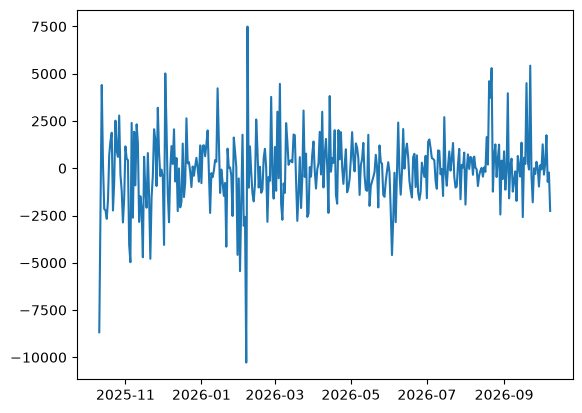

In [5]:
import matplotlib.pyplot as plt


plt.plot(data['price_diff'])
plt.show()